# Dense vs. hybrid retrieval performance

This notebook reads the JSON produced by `python -m scripts.evaluate_retrieval` and visualizes the measured Weaviate retrieval latency and any available relevance metrics. The evaluation uses the same queries and indexed corpus for dense retrieval and hybrid alpha values 0.25, 0.50, and 0.75.

**Interpretation:** retrieval latency is measured locally and excludes embedding generation. Latency alone does not establish better retrieval. Relevance metrics remain unavailable until candidate chunks have been manually reviewed. The workflow below pools each system's top-K candidates; its Recall@K is pool recall, not exhaustive recall over the collection.

In [17]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

project_root = Path.cwd()
if not (project_root / "app").is_dir():
    project_root = project_root.parent
results_path = project_root / "data" / "retrieval_eval_results.json"
if not results_path.exists():
    raise FileNotFoundError(
        f"{results_path} is missing. From the project root, run: "
        ".venv/Scripts/python.exe -m scripts.evaluate_retrieval"
    )

evaluation = json.loads(results_path.read_text(encoding="utf-8"))
print(f"Loaded: {results_path}")
print(f"K={evaluation['k']}; timed repeats={evaluation['latency_repeats']}; "
      f"queries/configuration={len(evaluation['results'][0]['queries'])}")

Loaded: c:\Users\Animatrix G14\Desktop\svm_assessment\rag_chatbot\data\retrieval_eval_results.json
K=5; timed repeats=3; queries/configuration=14


In [18]:
summary = []
for result in evaluation["results"]:
    alpha = "N/A" if result["alpha"] is None else f"{result['alpha']:.2f}"
    metrics = result["metrics"]
    latency = result["latency_ms"]
    summary.append({
        "mode": result["mode"],
        "alpha": alpha,
        "median retrieval ms": round(latency["median"], 2),
        "mean retrieval ms": round(latency["mean"], 2),
        ("Pool Recall@K" if evaluation.get("judgment_scope") else "Recall@K"): metrics["recall_at_k"],
        "Hit Rate@K": metrics["hit_rate_at_k"],
        "MRR": metrics["mrr"],
        "Precision@K": metrics["precision_at_k"],
        "judged queries": metrics["relevant_queries"],
        "unjudged queries": metrics["unjudged_queries"],
    })

display(summary)
recall_column = "Pool Recall@K" if evaluation.get("judgment_scope") else "Recall@K"
if all(row[recall_column] is None for row in summary):
    display(Markdown(
        "> **Quality metrics not measured:** relevance labels are missing. "
        "Only the local retrieval latency and returned rankings can be compared currently."
    ))

[{'mode': 'dense',
  'alpha': 'N/A',
  'median retrieval ms': 2.1,
  'mean retrieval ms': 2.1,
  'Pool Recall@K': 0.6805555555555557,
  'Hit Rate@K': 0.7857142857142857,
  'MRR': 0.544047619047619,
  'Precision@K': 0.31428571428571433,
  'judged queries': 14,
  'unjudged queries': 0},
 {'mode': 'hybrid',
  'alpha': '0.25',
  'median retrieval ms': 3.14,
  'mean retrieval ms': 3.16,
  'Pool Recall@K': 0.8125,
  'Hit Rate@K': 0.7857142857142857,
  'MRR': 0.7023809523809523,
  'Precision@K': 0.3857142857142858,
  'judged queries': 14,
  'unjudged queries': 0},
 {'mode': 'hybrid',
  'alpha': '0.50',
  'median retrieval ms': 3.24,
  'mean retrieval ms': 3.3,
  'Pool Recall@K': 0.7916666666666666,
  'Hit Rate@K': 0.7857142857142857,
  'MRR': 0.6452380952380953,
  'Precision@K': 0.3857142857142858,
  'judged queries': 14,
  'unjudged queries': 0},
 {'mode': 'hybrid',
  'alpha': '0.75',
  'median retrieval ms': 3.26,
  'mean retrieval ms': 3.32,
  'Pool Recall@K': 0.6944444444444443,
  'Hit Ra

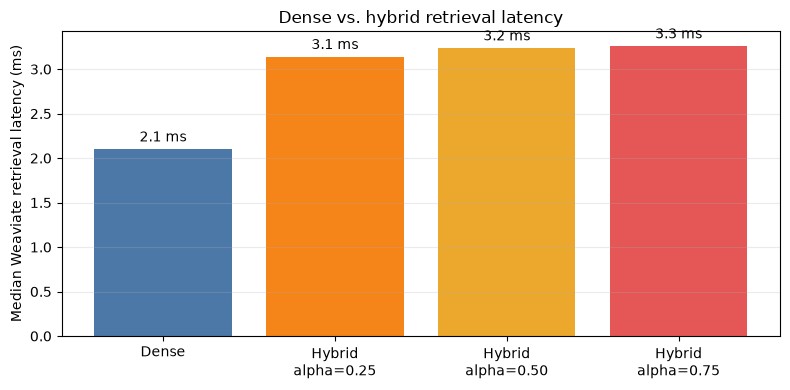

Hybrid alpha=0.25: +49.4% median latency vs dense
Hybrid alpha=0.50: +54.0% median latency vs dense
Hybrid alpha=0.75: +55.1% median latency vs dense


In [19]:
labels = [
    "Dense" if result["alpha"] is None else f"Hybrid\nalpha={result['alpha']:.2f}"
    for result in evaluation["results"]
]
latencies = [result["latency_ms"]["median"] for result in evaluation["results"]]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, latencies, color=["#4C78A8", "#F58518", "#ECA82C", "#E45756"])
ax.set_ylabel("Median Weaviate retrieval latency (ms)")
ax.set_title("Dense vs. hybrid retrieval latency")
ax.bar_label(bars, fmt="%.1f ms", padding=3)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

dense_ms = next(result["latency_ms"]["median"] for result in evaluation["results"]
                if result["mode"] == "dense")
for result in evaluation["results"]:
    if result["mode"] == "hybrid":
        change = (result["latency_ms"]["median"] / dense_ms - 1) * 100 if dense_ms else 0
        print(f"Hybrid alpha={result['alpha']:.2f}: {change:+.1f}% median latency vs dense")

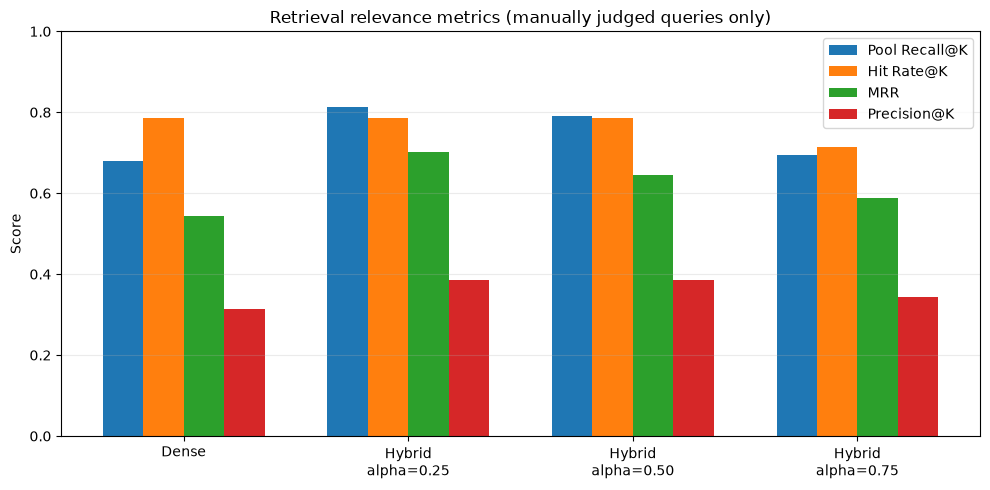

In [20]:
metric_keys = ["recall_at_k", "hit_rate_at_k", "mrr", "precision_at_k"]
if any(result["metrics"][key] is not None
       for result in evaluation["results"] for key in metric_keys):
    recall_label = "Pool Recall@K" if evaluation.get("judgment_scope") else "Recall@K"
    display_names = [recall_label, "Hit Rate@K", "MRR", "Precision@K"]
    x = list(range(len(evaluation["results"])))
    width = 0.18
    fig, ax = plt.subplots(figsize=(10, 5))
    for index, (key, name) in enumerate(zip(metric_keys, display_names)):
        values = [result["metrics"][key] for result in evaluation["results"]]
        if any(value is not None for value in values):
            ax.bar([position + (index - 1.5) * width for position in x],
                   [0 if value is None else value for value in values],
                   width, label=name)
    ax.set_xticks(x, labels)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title("Retrieval relevance metrics (manually judged queries only)")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()
else:
    print("No relevance metrics to plot. Add reviewed chunk UUIDs and rerun the evaluation.")

In [21]:
version_specific_ids = {"reporting-checklist-v1", "error-threshold-v2"}
for result in evaluation["results"]:
    for query in result["queries"]:
        if query["id"] in version_specific_ids:
            versions = sorted({item["version"] for item in query["results"]})
            print(f"{result['mode']} alpha={result['alpha']}: "
                  f"{query['id']} retrieved version(s) {versions}")

print("\nThis table demonstrates returned-version filtering; it is not a relevance score.")

dense alpha=None: reporting-checklist-v1 retrieved version(s) [1]
dense alpha=None: error-threshold-v2 retrieved version(s) [2]
hybrid alpha=0.25: reporting-checklist-v1 retrieved version(s) [1]
hybrid alpha=0.25: error-threshold-v2 retrieved version(s) [2]
hybrid alpha=0.5: reporting-checklist-v1 retrieved version(s) [1]
hybrid alpha=0.5: error-threshold-v2 retrieved version(s) [2]
hybrid alpha=0.75: reporting-checklist-v1 retrieved version(s) [1]
hybrid alpha=0.75: error-threshold-v2 retrieved version(s) [2]

This table demonstrates returned-version filtering; it is not a relevance score.


## Review relevance labels

Generate an annotation file from the union of chunks returned by all four retrieval configurations:

```bash
.venv/Scripts/python.exe -m scripts.prepare_retrieval_judgments
```

Open `data/retrieval_judgments.json`. For each question, read every candidate passage, add every supporting `chunk_id` to `relevant_chunk_ids`, and set `candidate_pool_reviewed` to `true` only after reviewing all candidates for that question. Leave it false while any candidate is undecided. Do not select chunks just because one mode retrieved them.

This is pooled judging: the candidate set is the union of the top-K results from the tested systems. The reported Recall@K is therefore **pool recall**, not exhaustive recall over every relevant chunk in the collection. After saving your judgments, rerun the evaluation with:

```bash
.venv/Scripts/python.exe -m scripts.evaluate_retrieval --judgments data/retrieval_judgments.json
```

Then rerun the notebook cells to see the judged quality metrics.

In [22]:
judgments_path = project_root / "data" / "retrieval_judgments.json"
if judgments_path.exists():
    judgment_template = json.loads(judgments_path.read_text(encoding="utf-8"))
    print("Available query IDs:", ", ".join(q["id"] for q in judgment_template["queries"]))
    query_to_review = "encoding-taxonomy-exact"  # Change this to review another query.
    query = next(q for q in judgment_template["queries"] if q["id"] == query_to_review)
    display(Markdown(f"### {query['id']}\n\n**Question:** {query['question']}"))
    for candidate in query["candidates"]:
        ranks = ", ".join(
            f"{item['mode']} α={item['alpha']} rank {item['rank']}"
            for item in candidate["retrieved_by"]
        )
        display(Markdown(
            f"**Chunk UUID:** `{candidate['chunk_id']}`  \n"
            f"**Paper:** arXiv:{candidate['arxiv_id']}v{candidate['version']}, "
            f"page {candidate['page']}, {candidate['section']}  \n"
            f"**Retrieved by:** {ranks}\n\n"
            f"> {candidate['text'].replace(chr(10), ' ')}"
        ))
    print("Edit this query's labels in data/retrieval_judgments.json after review.")
else:
    print("Create the template first with scripts.prepare_retrieval_judgments.")

Available query IDs: encoding-taxonomy-exact, low-error-encoding-paraphrase-v1, encoding-families, reporting-checklist-v1, error-threshold-v2, error-threshold-latest, qaml-scope, qaml-corresponding-author, feature-paper-v2-date, feature-paper-v1-affiliation, quantum-review-first-author, agentic-ai-workflow, latest-version-without-paper, semantic-keyword-qml


### encoding-taxonomy-exact

**Question:** What three axes does the paper use in its cost-expressivity-robustness taxonomy?

**Chunk UUID:** `012ea37e-b9df-5a44-b037-24b0c166e9d7`  
**Paper:** arXiv:2606.05387v1, page 9, methods [24] reduce this to O(𝐷) CNOTs at the cost of bounded approximation error.  
**Retrieved by:** hybrid α=0.25 rank 4

> er features, providing a classical approximation  framework for quantum kernel methods. Density-matrix encoding subsumes pure-state encoding as a special case and  allows the representation of classical probability distributions over inputs, but its practical circuit implementation is  Figure 2 visualises the three-axis taxonomy introduced in Contribution C1. The radar chart makes explicit the  structural trade-off that Table 2 encodes numerically: no encoding family dominates all three axes, and the Pareto

**Chunk UUID:** `581e520c-1c5d-57b6-870b-c7bc66ed3a9b`  
**Paper:** arXiv:2606.05387v1, page 1, 1 Introduction  
**Retrieved by:** dense α=None rank 4, hybrid α=0.25 rank 3, hybrid α=0.5 rank 3, hybrid α=0.75 rank 4

> works (2017–2026) assembled via a PRISMA-adapted  protocol across five academic databases. Four principal contributions are made. First, a three-axis cost–expressivity–robustness  taxonomy classifies all major encoding families—basis, angle, dense-angle, amplitude, data re-uploading, and IQP—along independently  measurable axes. Second, closed-form depth-fidelity bounds under nisq decoherence channels identify the critical gate-error rate  𝑝∗≈10−3 below which amplitude encoding is viable. Third, a unified treatment of Fourier expressivity, barren-plateau onset, and  quantum kernel concentration as functions of the encoding circuit provides the first joint trainability analysis. Fourth, a five-regime  decision framework maps (𝐷, 𝑛, 𝑝, 𝜏)—feature dimension, qubit budget, error rate, and task type—to a hardware-grounded encoding  The central finding is that for 𝑝≳10−3, shallow angle-based

**Chunk UUID:** `61e7edb7-aaf1-5f36-bd24-5f0343749e74`  
**Paper:** arXiv:2606.05387v1, page 24, methods: varia-  
**Retrieved by:** dense α=None rank 2, hybrid α=0.5 rank 4, hybrid α=0.75 rank 3

> is the fallback triggered by a failed fidelity check in Regime 4; annotation boxes (grey) state the relevant analytical expressions inline. All inputs are defined in ??.  Figure 4 plots the Pareto frontier in the two-dimensional space of expressivity (Fourier degree, as a proxy for model  capacity) vs. noise robustness (state-preparation fidelity at 𝑝2 = 3 × 10−3, 𝐷= 64). No encoding dominates all others  simultaneously: the frontier is monotone decreasing, confirming that expressivity and robustness are fundamentally at

**Chunk UUID:** `63c66845-2851-522f-8278-304a40a4ff5f`  
**Paper:** arXiv:2606.05387v1, page 10, methods [24] reduce this to O(𝐷) CNOTs at the cost of bounded approximation error.  
**Retrieved by:** dense α=None rank 1, hybrid α=0.25 rank 1, hybrid α=0.5 rank 1, hybrid α=0.75 rank 1

> g dominates all three axes simultaneously; the Pareto analysis in section 7 resolves this trilemma for specific hardware regimes.  frontier between expressivity and robustness (analysed quantitatively in section 7) is monotone decreasing. Amplitude  encoding occupies a unique position: it is simultaneously the most expressive and the most qubit-efficient strategy, but  its noise robustness score of 0.67 at 𝑝2 = 3 × 10−3 is the lowest in the comparison, a consequence of the O(𝐷) two-qubit  4 Embedding Costs: Theoretical and Practical Analysis  Before analysing individual encodings, we establish a precise cost taxonomy. Three classes of resource are relevant:

**Chunk UUID:** `8c2253ac-3026-5625-84a5-7a4cf87d4288`  
**Paper:** arXiv:2606.05387v1, page 10, methods [24] reduce this to O(𝐷) CNOTs at the cost of bounded approximation error.  
**Retrieved by:** dense α=None rank 3, hybrid α=0.25 rank 2, hybrid α=0.5 rank 2, hybrid α=0.75 rank 2

> e Degree-2 mono. Classically hard B [25] Amplitude ⌈log2 𝐷⌉ O(𝐷) O(𝐷) Exp. Full Hilbert Cosine / exp. D [24, 42] Density matrix 2⌈log2 𝐷⌉ O(𝐷2) O(𝐷) Exp. Full Hilbert Trace-dist. kernel D [21, 37]  Expressivity  Noise Robustness  gate count derived in proposition 1.  4.1 Taxonomy of Cost Metrics  1.00  0.75  0.50  0.25  Qubit Efficiency  Angle IQP (𝑘=2) · Re-up. (𝐿=3) · · · · · · Amplitude  Fig. 2. Three-axis cost–expressivity–robustness taxonomy for the four principal encoding families. Each axis is normalised to [0, 1]: Expressivity = log-normalised Fourier degree from theorem 1; Noise Robustness = encoding-layer fidelity 𝐹enc at 𝑝2 = 3 × 10−3, 𝐷= 64 from proposition 2; Qubit Efficiency = log2(𝐷) /𝑞(E, 𝐷), normalised so that amplitude encoding scores 1.00. No encoding dominates all three axes simultaneously; the Pareto analysis in section 7 resolves this trilemma for specific hardware

**Chunk UUID:** `eccd0a86-325e-5abf-8faa-0c916c0e0353`  
**Paper:** arXiv:2606.05387v1, page 2, 1 Introduction  
**Retrieved by:** dense α=None rank 5, hybrid α=0.25 rank 5, hybrid α=0.5 rank 5, hybrid α=0.75 rank 5

> et al. [62] catalogued encoding patterns as  software engineering constructs. However, none of these works:  • provides a formal, dimension-unified taxonomy in terms of qubit complexity, gate complexity, Fourier expressivity,  • derives closed-form bounds relating per-gate noise rate 𝑝, feature dimension 𝐷, and each encoding’s survivable  • connects barren-plateau theory and kernel-concentration theory to encoding families through a single analytical  • proposes a decision procedure backed by quantitative bounds rather than qualitative rules of thumb.  This survey makes the following original contributions:  • C1 — Three-axis taxonomy. We define the cost–expressivity–robustness space and place all major encoding  families within it, providing the first dimension-unified comparison (section 3, section 4).  • C2 — Analytical depth-fidelity bounds. We derive closed-form fidelity

Edit this query's labels in data/retrieval_judgments.json after review.
